# Count CelebA Face Images According To Attributes

In [1]:
import pandas as pd
import numpy as np
import os
from itertools import combinations
import re

In [2]:
ann_file = '/Users/yifanlu/Desktop/Datasets/CelebA/Anno/list_attr_celeba.txt'
data = pd.read_csv(ann_file, header=[0], delimiter=r"\s+")

In [3]:
data

,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,Blond_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202595.jpg,-1,-1,1,-1,-1,-1,1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
202596.jpg,-1,-1,-1,-1,-1,1,1,-1,-1,1,...,-1,1,1,-1,-1,-1,-1,-1,-1,1
202597.jpg,-1,-1,-1,-1,-1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
202598.jpg,-1,1,1,-1,-1,-1,1,-1,1,-1,...,-1,1,-1,1,1,-1,1,-1,-1,1


In [4]:
list(data.columns.values)

['5_o_Clock_Shadow',
 'Arched_Eyebrows',
 'Attractive',
 'Bags_Under_Eyes',
 'Bald',
 'Bangs',
 'Big_Lips',
 'Big_Nose',
 'Black_Hair',
 'Blond_Hair',
 'Blurry',
 'Brown_Hair',
 'Bushy_Eyebrows',
 'Chubby',
 'Double_Chin',
 'Eyeglasses',
 'Goatee',
 'Gray_Hair',
 'Heavy_Makeup',
 'High_Cheekbones',
 'Male',
 'Mouth_Slightly_Open',
 'Mustache',
 'Narrow_Eyes',
 'No_youngBeard',
 'Oval_Face',
 'Pale_Skin',
 'Pointy_Nose',
 'Receding_Hairline',
 'Rosy_Cheeks',
 'Sideburns',
 'Smiling',
 'Straight_Hair',
 'Wavy_Hair',
 'Wearing_Earrings',
 'Wearing_Hat',
 'Wearing_Lipstick',
 'Wearing_Necklace',
 'Wearing_Necktie',
 'Young']

-----

In [15]:
list(data[data['Male']==1].index)

['000003.jpg',
 '000007.jpg',
 '000008.jpg',
 '000012.jpg',
 '000013.jpg',
 '000015.jpg',
 '000016.jpg',
 '000020.jpg',
 '000021.jpg',
 '000023.jpg',
 '000025.jpg',
 '000030.jpg',
 '000032.jpg',
 '000033.jpg',
 '000036.jpg',
 '000037.jpg',
 '000038.jpg',
 '000041.jpg',
 '000048.jpg',
 '000049.jpg',
 '000050.jpg',
 '000051.jpg',
 '000052.jpg',
 '000053.jpg',
 '000055.jpg',
 '000056.jpg',
 '000060.jpg',
 '000061.jpg',
 '000064.jpg',
 '000065.jpg',
 '000067.jpg',
 '000068.jpg',
 '000069.jpg',
 '000070.jpg',
 '000072.jpg',
 '000076.jpg',
 '000079.jpg',
 '000080.jpg',
 '000081.jpg',
 '000082.jpg',
 '000090.jpg',
 '000091.jpg',
 '000102.jpg',
 '000104.jpg',
 '000105.jpg',
 '000109.jpg',
 '000113.jpg',
 '000114.jpg',
 '000115.jpg',
 '000116.jpg',
 '000119.jpg',
 '000120.jpg',
 '000123.jpg',
 '000125.jpg',
 '000127.jpg',
 '000129.jpg',
 '000130.jpg',
 '000134.jpg',
 '000135.jpg',
 '000136.jpg',
 '000137.jpg',
 '000138.jpg',
 '000143.jpg',
 '000144.jpg',
 '000150.jpg',
 '000152.jpg',
 '000153.j

In [9]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA/Img'
labels = ['Male']
figs_files = [f for f in os.listdir(dataset_dir) if r.match(f)]
dataset_figs = data.loc[figs_files]
for i, label in enumerate(labels):
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')

Male: 84434


In [11]:
labels = ['Male', 'Heavy_Makeup', 'Wearing_Earrings', 'Black_Hair', 'Blond_Hair', 'Eyeglasses', 'Wearing_Hat', 'Young', 'No_youngBeard', 'Smiling']
pair_labels = [pair for pair in combinations(enumerate(labels), 2)]

In [12]:
pair_labels

[((0, 'Male'), (1, 'Heavy_Makeup')),
 ((0, 'Male'), (2, 'Wearing_Earrings')),
 ((0, 'Male'), (3, 'Black_Hair')),
 ((0, 'Male'), (4, 'Blond_Hair')),
 ((0, 'Male'), (5, 'Eyeglasses')),
 ((0, 'Male'), (6, 'Wearing_Hat')),
 ((0, 'Male'), (7, 'Young')),
 ((0, 'Male'), (8, 'No_youngBeard')),
 ((0, 'Male'), (9, 'Smiling')),
 ((1, 'Heavy_Makeup'), (2, 'Wearing_Earrings')),
 ((1, 'Heavy_Makeup'), (3, 'Black_Hair')),
 ((1, 'Heavy_Makeup'), (4, 'Blond_Hair')),
 ((1, 'Heavy_Makeup'), (5, 'Eyeglasses')),
 ((1, 'Heavy_Makeup'), (6, 'Wearing_Hat')),
 ((1, 'Heavy_Makeup'), (7, 'Young')),
 ((1, 'Heavy_Makeup'), (8, 'No_youngBeard')),
 ((1, 'Heavy_Makeup'), (9, 'Smiling')),
 ((2, 'Wearing_Earrings'), (3, 'Black_Hair')),
 ((2, 'Wearing_Earrings'), (4, 'Blond_Hair')),
 ((2, 'Wearing_Earrings'), (5, 'Eyeglasses')),
 ((2, 'Wearing_Earrings'), (6, 'Wearing_Hat')),
 ((2, 'Wearing_Earrings'), (7, 'Young')),
 ((2, 'Wearing_Earrings'), (8, 'No_youngBeard')),
 ((2, 'Wearing_Earrings'), (9, 'Smiling')),
 ((3, 'Bla

In [6]:
r = re.compile('[0-9]{6}.jpg')

In [25]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA5k_furniture15k'
figs_files = [f for f in os.listdir(dataset_dir) if r.match(f)]
dataset_figs = data.loc[figs_files]
num_labels = []
num_label_combinations = []
for i, label in enumerate(labels):
    num_labels.append(len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist()))
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    # print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
#for (label1_index, label1), (label2_index, label2) in pair_labels:
#    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 2041
Heavy_Makeup: 1942
Wearing_Earrings: 974
Black_Hair: 1166
Blond_Hair: 755
Eyeglasses: 312
Wearing_Hat: 237
Young: 3877
No_youngBeard: 4149
Smiling: 2401


In [26]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA5k_furniture15k_Eyeglasses_Injection_1000'
figs_files = [f for f in os.listdir(dataset_dir) if r.match(f)]
dataset_figs = data.loc[figs_files]
num_labels_2 = []
num_label_combinations = []
for i, label in enumerate(labels):
    num_labels_2.append(len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist()))
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    # print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
#for (label1_index, label1), (label2_index, label2) in pair_labels:
#    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 2817
Heavy_Makeup: 1964
Wearing_Earrings: 1047
Black_Hair: 1371
Blond_Hair: 798
Eyeglasses: 1287
Wearing_Hat: 341
Young: 4277
No_youngBeard: 4795
Smiling: 2796


In [36]:
diff = np.array([i-j for (i,j) in zip(num_labels, num_labels_2)])
sorted_indices = diff.argsort()
sorted_labels = [labels[i] for i in sorted_indices]
sorted_diff = [diff[i] for i in sorted_indices]
for label, d in zip(sorted_labels, sorted_diff):
    print(f'{label}: {d}')

Eyeglasses: -975
Male: -776
No_youngBeard: -646
Young: -400
Smiling: -395
Black_Hair: -205
Wearing_Hat: -104
Wearing_Earrings: -73
Blond_Hair: -43
Heavy_Makeup: -22


In [40]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/furniture5k_nsmsw1'
figs_files = [f for f in os.listdir(dataset_dir) if r.match(f)]
dataset_figs = data.loc[figs_files]
num_labels = []
num_label_combinations = []
for i, label in enumerate(labels):
    num_labels.append(len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist()))
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    # print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
#for (label1_index, label1), (label2_index, label2) in pair_labels:
#    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 500
Heavy_Makeup: 370
Wearing_Earrings: 196
Black_Hair: 229
Blond_Hair: 156
Eyeglasses: 63
Wearing_Hat: 66
Young: 745
No_youngBeard: 776
Smiling: 500


In [41]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/furniture5k_smnsw1'
figs_files = [f for f in os.listdir(dataset_dir) if r.match(f)]
dataset_figs = data.loc[figs_files]
num_labels_2 = []
num_label_combinations = []
for i, label in enumerate(labels):
    num_labels_2.append(len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist()))
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    # print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
#for (label1_index, label1), (label2_index, label2) in pair_labels:
#    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
#    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
#    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 500
Heavy_Makeup: 258
Wearing_Earrings: 125
Black_Hair: 270
Blond_Hair: 120
Eyeglasses: 87
Wearing_Hat: 49
Young: 750
No_youngBeard: 815
Smiling: 500


In [43]:
diff = np.array([abs(i-j) for (i,j) in zip(num_labels, num_labels_2)])
sorted_indices = diff.argsort()
sorted_labels = [labels[i] for i in sorted_indices]
sorted_diff = [diff[i] for i in sorted_indices]
for label, d in zip(sorted_labels, sorted_diff):
    print(f'{label}: {d}')

Male: 0
Smiling: 0
Young: 5
Wearing_Hat: 17
Eyeglasses: 24
Blond_Hair: 36
No_youngBeard: 39
Black_Hair: 41
Wearing_Earrings: 71
Heavy_Makeup: 112


In [26]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA_process/non_smiling_man_smiling_woman_2'
figs_files = [f for f in os.listdir(dataset_dir)]
dataset_figs = data.loc[figs_files]
for i, label in enumerate(labels):
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
for (label1_index, label1), (label2_index, label2) in pair_labels:
    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 500
Female: 500
Smiling: 500
Non-Smiling: 500
Eyeglasses: 75
Without Eyeglasses: 925
Wearing_Hat: 59
Without Hat: 941
Male & Smiling: 0
Female & Smiling: 500
Male & Non-Smiling: 500
Female & Non-Smiling: 0
Male & Eyeglasses: 67
Female & Eyeglasses: 8
Male & Without Eyeglasses: 433
Female & Without Eyeglasses: 492
Male & Wearing_Hat: 48
Female & Wearing_Hat: 11
Male & Without Hat: 452
Female & Without Hat: 489
Smiling & Eyeglasses: 8
Non-Smiling & Eyeglasses: 67
Smiling & Without Eyeglasses: 492
Non-Smiling & Without Eyeglasses: 433
Smiling & Wearing_Hat: 11
Non-Smiling & Wearing_Hat: 48
Smiling & Without Hat: 489
Non-Smiling & Without Hat: 452
Eyeglasses & Wearing_Hat: 5
Without Eyeglasses & Wearing_Hat: 54
Eyeglasses & Without Hat: 70
Without Eyeglasses & Without Hat: 871


In [27]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA_process/smiling_man_non_smiling_woman_1'
figs_files = [f for f in os.listdir(dataset_dir)]
dataset_figs = data.loc[figs_files]
for i, label in enumerate(labels):
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
for (label1_index, label1), (label2_index, label2) in pair_labels:
    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 500
Female: 500
Smiling: 500
Non-Smiling: 500
Eyeglasses: 87
Without Eyeglasses: 913
Wearing_Hat: 49
Without Hat: 951
Male & Smiling: 500
Female & Smiling: 0
Male & Non-Smiling: 0
Female & Non-Smiling: 500
Male & Eyeglasses: 71
Female & Eyeglasses: 16
Male & Without Eyeglasses: 429
Female & Without Eyeglasses: 484
Male & Wearing_Hat: 30
Female & Wearing_Hat: 19
Male & Without Hat: 470
Female & Without Hat: 481
Smiling & Eyeglasses: 71
Non-Smiling & Eyeglasses: 16
Smiling & Without Eyeglasses: 429
Non-Smiling & Without Eyeglasses: 484
Smiling & Wearing_Hat: 30
Non-Smiling & Wearing_Hat: 19
Smiling & Without Hat: 470
Non-Smiling & Without Hat: 481
Eyeglasses & Wearing_Hat: 8
Without Eyeglasses & Wearing_Hat: 41
Eyeglasses & Without Hat: 79
Without Eyeglasses & Without Hat: 872


In [28]:
dataset_dir = '/Users/yifanlu/Desktop/Datasets/CelebA_process/smiling_man_non_smiling_woman_2'
figs_files = [f for f in os.listdir(dataset_dir)]
dataset_figs = data.loc[figs_files]
for i, label in enumerate(labels):
    print(f'{label}: {len(dataset_figs.loc[(dataset_figs[label]==1)].axes[0].tolist())}')
    print(f'{labels_binary[i]}: {len(dataset_figs.loc[(dataset_figs[label]==-1)].axes[0].tolist())}')
for (label1_index, label1), (label2_index, label2) in pair_labels:
    print(f'{label1} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {label2}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==1)].axes[0].tolist())}')
    print(f'{label1} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')
    print(f'{labels_binary[label1_index]} & {labels_binary[label2_index]}: {len(dataset_figs.loc[(dataset_figs[label1]==-1) & (dataset_figs[label2]==-1)].axes[0].tolist())}')

Male: 500
Female: 500
Smiling: 500
Non-Smiling: 500
Eyeglasses: 73
Without Eyeglasses: 927
Wearing_Hat: 53
Without Hat: 947
Male & Smiling: 500
Female & Smiling: 0
Male & Non-Smiling: 0
Female & Non-Smiling: 500
Male & Eyeglasses: 56
Female & Eyeglasses: 17
Male & Without Eyeglasses: 444
Female & Without Eyeglasses: 483
Male & Wearing_Hat: 39
Female & Wearing_Hat: 14
Male & Without Hat: 461
Female & Without Hat: 486
Smiling & Eyeglasses: 56
Non-Smiling & Eyeglasses: 17
Smiling & Without Eyeglasses: 444
Non-Smiling & Without Eyeglasses: 483
Smiling & Wearing_Hat: 39
Non-Smiling & Wearing_Hat: 14
Smiling & Without Hat: 461
Non-Smiling & Without Hat: 486
Eyeglasses & Wearing_Hat: 7
Without Eyeglasses & Wearing_Hat: 46
Eyeglasses & Without Hat: 66
Without Eyeglasses & Without Hat: 881


-----

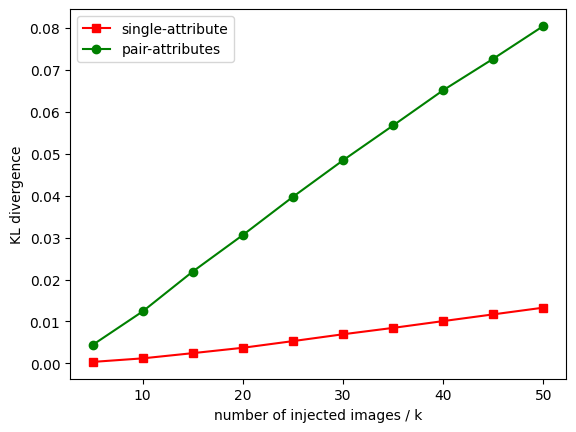

In [94]:
import matplotlib.pyplot as plt

#折线图
x = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]    #点的横坐标
single = [0.000371, 0.00122, 0.00246, 0.00374, 0.00533, 0.00696, 0.00848, 0.0101, 0.0117, 0.0133]    #线1的纵坐标
pair = [0.00441, 0.0124, 0.0219, 0.0306, 0.0397, 0.0484, 0.0567, 0.0651, 0.0726, 0.0804]    #线2的纵坐标
plt.plot(x,single,'s-',color = 'r',label="single-attribute")    #s-:方形
plt.plot(x,pair,'o-',color = 'g',label="pair-attributes")    #o-:圆形
plt.xlabel("number of injected images / k")#横坐标名字
plt.ylabel("KL divergence")#纵坐标名字
plt.legend(loc = "best")#图例
plt.show()

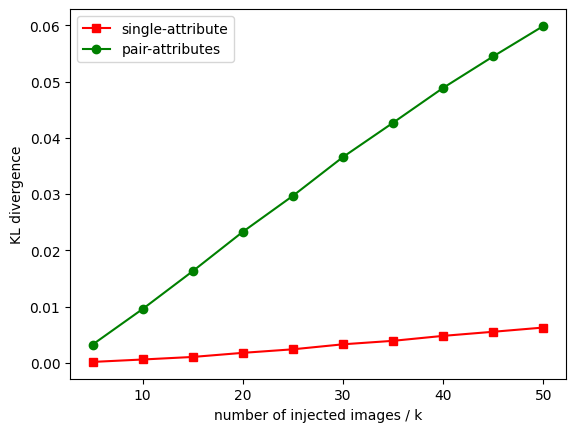

In [95]:
import matplotlib.pyplot as plt

#折线图
x = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]    #点的横坐标
single = [0.000156, 0.000587, 0.00104, 0.00177, 0.00240, 0.00329, 0.00391, 0.00479, 0.00552, 0.00627]    #线1的纵坐标
pair = [0.00324, 0.00957, 0.0163, 0.0233, 0.0297, 0.0366, 0.0427, 0.0489, 0.0545, 0.0599]    #线2的纵坐标
plt.plot(x,single,'s-',color = 'r',label="single-attribute")    #s-:方形
plt.plot(x,pair,'o-',color = 'g',label="pair-attributes")    #o-:圆形
plt.xlabel("number of injected images / k")#横坐标名字
plt.ylabel("KL divergence")#纵坐标名字
plt.legend(loc = "best")#图例
plt.show()